# 03 - Volatility smiles and surface (SYNTHETIC European data)
The chain is generated offline from a known SSVI surface with seeded noise and deliberately injected bad quotes. **Not market data.**

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from optpricer import Option, MarketData, price, price_all, bsm
pd.set_option("display.width", 160); pd.set_option("display.precision", 6)

In [2]:
from optpricer.market import synthetic_european_chain, clean_chain, cleaning_summary, CleaningPolicy
from optpricer.surface import implied_forwards, build_smiles, arbitrage_diagnostics, TotalVarianceSurface
chain, truth = synthetic_european_chain(seed=7)
cl = clean_chain(chain, CleaningPolicy(r=truth["r"], q=truth["q"]))
display(cleaning_summary(cl))
display(cl.loc[cl.injected_defect != "", ["kind", "strike", "T", "bid", "ask", "injected_defect", "reasons"]])

,reason,count
0,zero_bid,27
1,wide_spread,4
2,bound_violation,2
3,stale_quote,2
4,crossed_market,2
5,negative_quote,1
6,missing_quote,1
7,TOTAL_REJECTED_ROWS,37
8,TOTAL_ACCEPTED_ROWS,455


,kind,strike,T,bid,ask,injected_defect,reasons
2,call,70.0,0.082192,0.00,30.62,zero_bid,zero_bid;wide_spread
33,call,120.0,0.082192,-0.05,0.02,negative_quote,negative_quote
50,put,90.0,0.082192,0.60,NaN,missing_quote,missing_quote
117,call,125.0,0.164384,101.00,101.20,bound_violation,bound_violation
214,put,90.0,0.249315,0.00,1.57,zero_bid,zero_bid;wide_spread
220,put,96.0,0.249315,2.57,2.68,stale_quote,stale_quote
225,put,101.0,0.249315,4.35,4.14,crossed_market,crossed_market
243,put,140.0,0.249315,39.92,38.66,crossed_market,crossed_market
295,put,87.5,0.498630,0.64,6.03,wide_spread,wide_spread
327,put,150.0,0.498630,47.81,49.30,stale_quote,stale_quote


In [3]:
fw = implied_forwards(cl, n_near=25)
fw["F_true"] = [e["F"] for e in truth["expiries"]]; fw["DF_true"] = [e["DF"] for e in truth["expiries"]]
display(fw[["expiry", "T", "F", "F_se", "F_true", "DF", "DF_se", "DF_true", "n_pairs"]])

,expiry,T,F,F_se,F_true,DF,DF_se,DF_true,n_pairs
0,2026-02-14,0.082192,100.121520,0.003315,100.123364,0.997858,0.000562,0.997537,25
1,2026-03-16,0.164384,100.238386,0.003883,100.246880,0.994927,0.000613,0.995081,25
2,2026-04-16,0.249315,100.374362,0.004247,100.374673,0.992623,0.000563,0.992548,25
3,2026-07-16,0.498630,100.749893,0.004575,100.750749,0.983818,0.000640,0.985152,25
4,2027-01-15,1.000000,101.513581,0.006417,101.511306,0.971282,0.000797,0.970446,25
5,2028-01-15,2.000000,103.031854,0.008751,103.045453,0.941943,0.001022,0.941765,25


max |IV - true IV| on cleaned OTM quotes: 0.008264296391008452


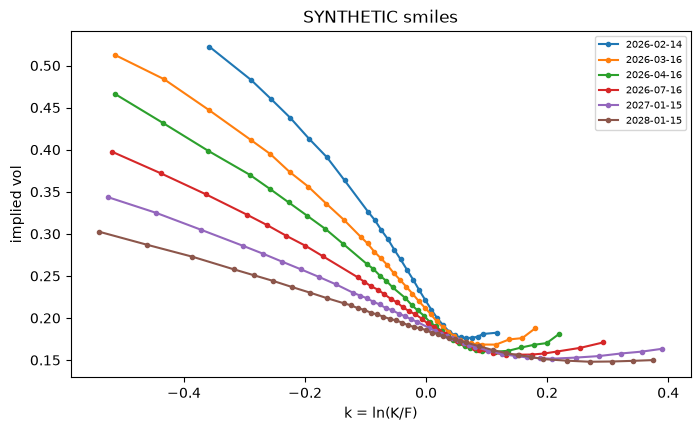

In [4]:
sm = build_smiles(cl, fw)
fig, ax = plt.subplots(figsize=(8, 4.5))
for exp, g in sm.groupby("expiry"):
    g = g.sort_values("k"); ax.plot(g.k, g.iv, marker=".", label=exp)
ax.set_xlabel("k = ln(K/F)"); ax.set_ylabel("implied vol"); ax.legend(fontsize=7); ax.set_title("SYNTHETIC smiles")
print("max |IV - true IV| on cleaned OTM quotes:", sm.iv_error_vs_true.abs().max() if "iv_error_vs_true" in sm else (sm.iv - sm.true_iv).abs().max())

In [5]:
viol, summ = arbitrage_diagnostics(cl, fw, sm)
display(summ)
display(viol.head(10))

,check,violations_mid,violations_executable,max_magnitude
0,bounds,12,0,0.161649
1,monotonicity,10,0,0.200709
2,vertical_spread,1,0,0.015741
3,convexity,36,0,0.132500
4,calendar,0,0,0.000000


,expiry,check,strikes,magnitude,basis,executable
0,2026-02-14,bounds,120,0.030904,mid,False
1,2026-02-14,bounds,122.5,0.025549,mid,False
2,2026-02-14,bounds,125,0.065195,mid,False
3,2026-02-14,bounds,130,0.114486,mid,False
4,2026-02-14,bounds,135,0.088776,mid,False
5,2026-02-14,bounds,150,0.161649,mid,False
6,2026-02-14,vertical_spread,65/70,0.015741,mid,False
7,2026-02-14,monotonicity,115/117.5,0.045355,mid,False
8,2026-02-14,monotonicity,120/122.5,0.005355,mid,False
9,2026-02-14,monotonicity,130/135,0.025709,mid,False


Mid-price inconsistencies appear because of quote noise and tick rounding, but none is executable at the quoted bid/ask. Passing finite-grid checks would still not prove that a continuous surface is arbitrage-free. American-style equity quotes (e.g. SPY) are refused by these European tools unless an explicit, labelled approximation is requested.